# Week 3 Practice: K-Means Clustering and PCA

## Objectives
1. Apply K-Means clustering to the Iris dataset.
2. Display the cluster centers.
3. Visualize the clusters using Matplotlib.
4. Apply PCA to reduce the dataset to two dimensions.
5. Calculate the explained variance ratio.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [3]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("Dataset shape:", X.shape)
print("\nFirst five rows:")
print(X.head())

Dataset shape: (150, 4)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (150, 4)


In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print("Cluster centers:")
print(kmeans.cluster_centers_)

print("\nCluster counts:")
print(pd.Series(clusters).value_counts().sort_index())

Cluster centers:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

Cluster counts:
0    53
1    50
2    47
Name: count, dtype: int64


C:\Users\pc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [7]:
centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    centers,
    columns=X.columns
)

print("Cluster centers in original units:")
print(centers_df.round(2))

Cluster centers in original units:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0               5.80              2.67               4.37              1.41
1               5.01              3.43               1.46              0.25
2               6.78              3.10               5.51              1.97


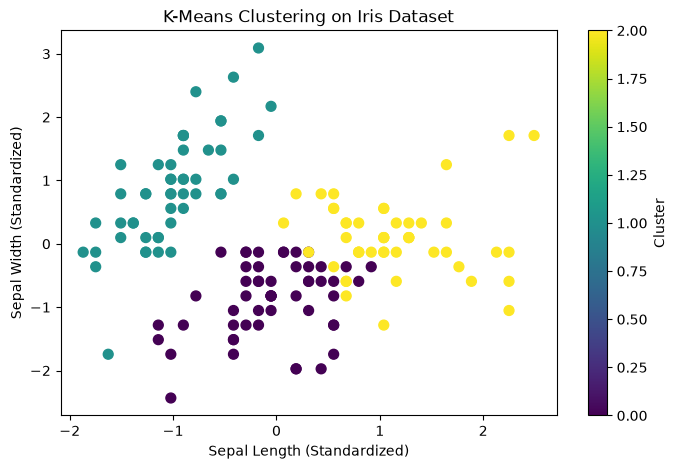

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("K-Means Clustering on Iris Dataset")
plt.colorbar(label="Cluster")
plt.show()

In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original dataset shape:", X.shape)
print("PCA dataset shape:", X_pca.shape)

print("\nFirst five PCA rows:")
print(X_pca[:5])

Original dataset shape: (150, 4)
PCA dataset shape: (150, 2)

First five PCA rows:
[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]


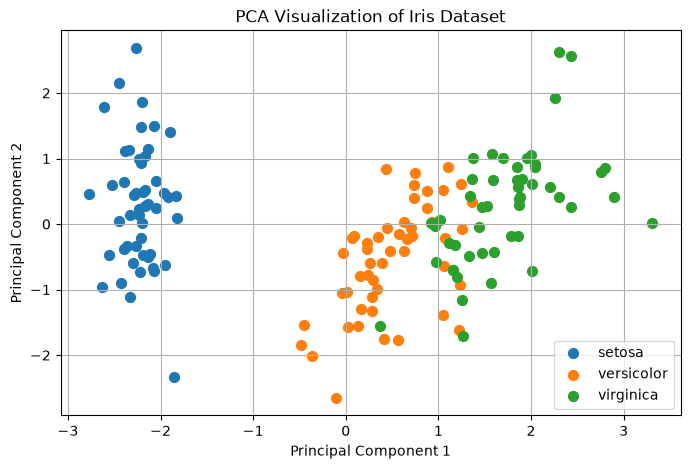

In [10]:
plt.figure(figsize=(8, 5))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=species,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
variance_ratio = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(variance_ratio)

print("\nPC1 variance:",
      round(variance_ratio[0] * 100, 2), "%")

print("PC2 variance:",
      round(variance_ratio[1] * 100, 2), "%")

print("Total variance explained:",
      round(variance_ratio.sum() * 100, 2), "%")

Explained variance ratio:
[0.72962445 0.22850762]

PC1 variance: 72.96 %
PC2 variance: 22.85 %
Total variance explained: 95.81 %


## Conclusion

K-Means clustering was applied to the Iris dataset to group flowers into three clusters, and the cluster centers were displayed in both standardized and original feature units. Matplotlib was used to visualize the clusters. PCA was then applied to reduce the four-dimensional dataset to two principal components. The explained variance ratio showed that the two components preserve approximately 95.81% of the total variance. These exercises demonstrate the usefulness of clustering for discovering groups in data and dimensionality reduction for simplifying datasets and visualizing their structure.